<a href="https://colab.research.google.com/github/Elizabeth2061/MN_Lab_PRUDKA/blob/main/%D0%9B%D0%A0_2_2_%D0%9F%D1%80%D1%83%D0%B4%D0%BA%D0%B0_%D0%84_%D0%9E__4_8_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Була присутня на парі

In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Зчитаємо напряму з кагл

https://www.kaggle.com/datasets/mahmoudshogaa/titanic-dataset

In [34]:
import kagglehub
import os

path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")

print ("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [35]:
df = pd.read_csv(os.path.join(path, "titanic.csv"))

df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


PassengerId: унікальний ідентифікатор для кожного пасажира.

Вижив: у цій колонці вказано, чи вижив пасажир (1) чи не вижив (0).

Pclass (клас квитків): проксі для соціально-економічного статусу, де 1 є найвищим класом, а 3 найнижчим.

Ім'я: Ім'я пасажира.

Стать: Стать пасажира.

Вік: Вік пасажира. (Примітка: у цьому стовпці можуть бути відсутні значення)

SibSp: кількість братів і сестер або подружжя, які були у пасажира на борту "Титаніка".

Парч: кількість батьків або дітей, які були у пасажира на борту "Титаніка".

Квиток: Номер квитка.

Вартість проїзду: сума грошей, яку пасажир заплатив за квиток.

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [39]:
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))

df.drop (['Cabin'], axis=1, inplace=True)
df.drop(['Embarked'], axis=1, inplace=True)

In [40]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [41]:
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]

df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


In [42]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [43]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')

Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


/tmp/ipykernel_1496/275882515.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})


In [44]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


In [45]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


In [46]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


In [47]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


In [49]:
survival_by_sex = df.groupby('Sex') ['Survived'].mean() * 100

print(f'Share of survived males: {survival_by_sex[0]:.2f}%')
print(f'Share of survived females: {survival_by_sex[1]:.2f}%')

Share of survived males: 18.89%
Share of survived females: 74.20%


In [50]:
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"])}')

Correlation between sex and survival: 0.5433513806577555


In [51]:
class1_surv_rate = df[(df['Pclass'] == 1) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 1].shape[0]
class2_surv_rate = df[(df['Pclass'] == 2) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 2].shape[0]
class3_surv_rate = df[(df['Pclass'] == 3) & (df['Survived'] == 1)].shape[0] / df[df['Pclass'] == 3].shape[0]

print(f'Share of survived class 1 passengers {class1_surv_rate * 100:.2f}%')
print (f'Share of survived class 2 passengers {class2_surv_rate * 100:.2f}%')
print(f'Share of survived class 3 passengers {class3_surv_rate * 100:.2f}%')

Share of survived class 1 passengers 62.96%
Share of survived class 2 passengers 47.28%
Share of survived class 3 passengers 24.24%


Серед пасажирів 1го класу було більше виживших.

In [53]:
survived_mean_age = df[df['Survived'] == 1] ['Age'].mean()
not_survived_mean_age = df[df['Survived'] == 0]['Age'].mean()

print(f'Mean age of survived passengers: {survived_mean_age:.2f}')
print(f'Mean age of not survived passengers: {not_survived_mean_age:.2f}')

Mean age of survived passengers: 28.29
Mean age of not survived passengers: 30.03


Вік не впливає на виживання

In [58]:
df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)

for i in range(6):
      surv_rate = df[(df['Fare_Category'] == i) & (df['Survived'] == 1)].shape[0] / df[df['Fare_Category'] == i].shape[0]
      print(f'Share of survived passengers in bucket {i}: {surv_rate * 100:.2f}%')

Share of survived passengers in bucket 0: 20.51%
Share of survived passengers in bucket 1: 19.08%
Share of survived passengers in bucket 2: 36.69%
Share of survived passengers in bucket 3: 43.62%
Share of survived passengers in bucket 4: 41.78%
Share of survived passengers in bucket 5: 69.80%


/tmp/ipykernel_1496/787059136.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)


Пасажири з дорожчими квитками мали вищий шас на виживання

In [60]:
for i in range(1, 4):
  median_fare = df[df['Pclass'] == i]['Fare'].median()
  print(f'Median fare for class {i}: {median_fare:.2f}')

Median fare for class 1: 60.29
Median fare for class 2: 14.25
Median fare for class 3: 8.05


Ціни на квитки першого класу значно дорожчі за другий та третій класи. Коли різниця між третім та другим у 2 рази, то між другим та першим майже 4 рази.

<Axes: xlabel='Age', ylabel='Count'>

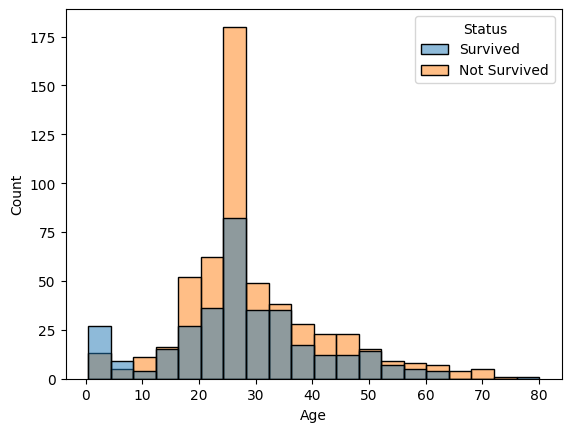

In [61]:
df_survived = df[df['Survived'] == 1] [['Age']]
df_survived['Status'] = 'Survived'

df_not_survived = df[df['Survived'] == 0] [['Age']]
df_not_survived ['Status'] = 'Not Survived'

df_combined = pd.concat([df_survived, df_not_survived])

sns.histplot(data=df_combined, x='Age', hue='Status', bins=20)

На гістограмі видно, що найбільше пасажирів було у віці від 20 до 30 років. У цій категорії кількість загиблих значно перевищує кількість тих, хто вижив.

Серед дітей і підлітків до 20 років частіше зустрічаються ті, хто вижив. Це може бути пов’язано з тим, що під час евакуації перевагу надавали дітям.

У вікових групах від 30 до 50 років загиблих також більше, ніж тих, хто врятувався, проте різниця не така велика, як серед пасажирів віком 20–30 років.

Пасажирів старше 50 років було значно менше. У цих групах співвідношення між тими, хто вижив, і загиблими є більш рівномірним. У найстаршій категорії, від 70 років, пасажирів зовсім мало, але тих, хто вижив, більше.

Отже, можна зробити висновок, що вік впливав на шанси вижити під час катастрофи «Титаніка». Найбільше загиблих було серед молодих дорослих, тоді як діти мали відносно кращі шанси врятуватися.

In [62]:
for i in range(1, 4):
  for j in range(2):
    surv_rate = df[(df['Pclass'] == i) & (df['Sex'] == j) & (df['Survived'] == 1)].shape[0] / df[(df['Pclass'] == i) & (df['Sex'] == j)].shape[0]
    print(f'Share of survived {"male " if j == 0 else "female"} passengers in class {i}: {surv_rate * 100:.2f}%')

Share of survived male  passengers in class 1: 36.89%
Share of survived female passengers in class 1: 96.81%
Share of survived male  passengers in class 2: 15.74%
Share of survived female passengers in class 2: 92.11%
Share of survived male  passengers in class 3: 13.54%
Share of survived female passengers in class 3: 50.00%


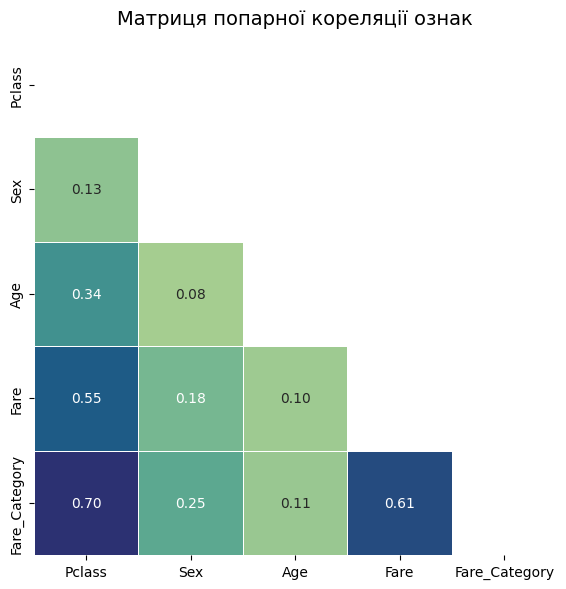

In [64]:
mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(6, 6))

sns.heatmap(
  mtx,
  cmap='crest',
  annot=True,
  fmt=".2f",
  linewidths=0.5,
  mask=np.triu(np.ones_like (mtx, dtype=bool)), # маскуємо верхній трикутник
  square=True,
  cbar=False,
  ax=ax
)

plt.title ("Матриця попарної кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

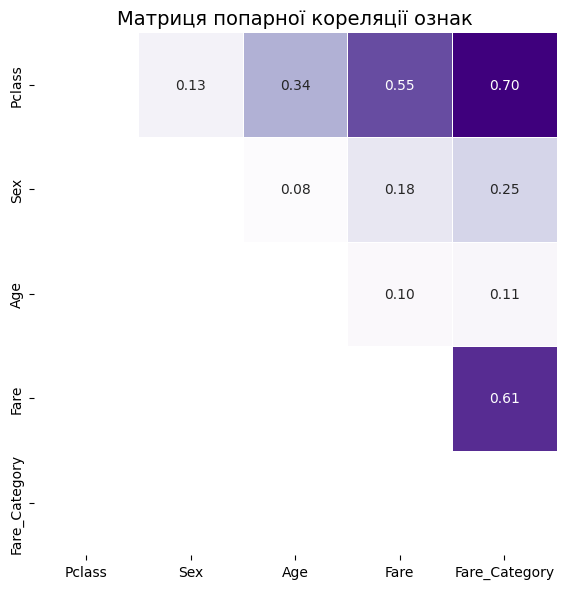

In [67]:
mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(6, 6))

sns.heatmap(
  mtx,
  cmap='Purples',
  annot=True,
  fmt=".2f",
  linewidths=0.5,
  mask=np.tril(np.ones_like(mtx, dtype=bool)),  # маскуємо нижній трикутник
  square=True,
  cbar=False,
  ax=ax
)

plt.title ("Матриця попарної кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

Аналіз даних "Коефіцієнт народжуваності в регіонах України (1950—2019)"

In [69]:
import pandas as pd
import requests
from io import StringIO

url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22%27'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


In [70]:
import numpy as np
import matplotlib.pyplot as plt

# Перегляд структури датасету
print("Розмір датасету:", df.shape)
print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nТипи даних:")
print(df.dtypes)

print("\nПропущені значення:")
print(df.isnull().sum())

print("\nКількість дублікатів:", df.duplicated().sum())

print("\nОписова статистика:")
print(df.describe())

Розмір датасету: (28, 9)

Назви стовпців:
['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014', '2019']

Типи даних:
Регіон     object
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014       object
2019       object
dtype: object

Пропущені значення:
Регіон    0
1950      2
1960      1
1970      1
1990      0
2000      0
2012      0
2014      0
2019      0
dtype: int64

Кількість дублікатів: 0

Описова статистика:
            1950       1960       1970       1990       2000       2012
count  26.000000  27.000000  27.000000  28.000000  28.000000  28.000000
mean   23.092308  20.748148  15.585185  13.042857   8.207143  11.646429
std     2.822045   2.936032   1.870357   1.527872   1.556808   1.636274
min    18.600000  16.300000  12.700000  10.800000   6.100000   9.400000
25%    21.150000  18.650000  14.400000  12.225000   7.075000  10.450000
50%    22.600000  20.400000  15.200000  12.600000   7.850000  11.450000
75

In [71]:
# Якщо назви стовпців багаторівневі, перетворюємо їх на звичайні
if isinstance(df.columns, pd.MultiIndex):
    df.columns = [
        " ".join(str(x) for x in col if str(x) != "nan").strip()
        for col in df.columns
    ]

df.columns = [str(col).strip() for col in df.columns]

# Перейменування першого стовпця
df = df.rename(columns={df.columns[0]: "Регіон"})

# Визначення стовпців із роками
year_cols = [
    col for col in df.columns
    if any(str(year) in col for year in range(1950, 2020))
]

# Перетворення показників на числа
for col in year_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace("\xa0", "", regex=False)
        .str.replace(",", ".", regex=False)
        .replace({"—": np.nan, "-": np.nan, "nan": np.nan}),
        errors="coerce"
    )

print("Розмір після підготовки:", df.shape)
print(df.head())

Розмір після підготовки: (28, 9)
             Регіон  1950  1960  1970  1990  2000  2012  2014  2019
0              Крим  23.0  20.6  16.0  13.0   7.3  12.6   NaN   NaN
1         Вінницька  22.4  19.2  14.2  12.4   8.4  11.2  10.9   7.6
2         Волинська  24.7  25.0  17.9  15.3  11.2  14.8  14.1  10.1
3  Дніпропетровська  20.4  20.4  15.1  12.3   7.1  11.2  11.1   7.1
4          Донецька  27.1  21.4  14.0  10.9   6.1   9.8   8.2   NaN


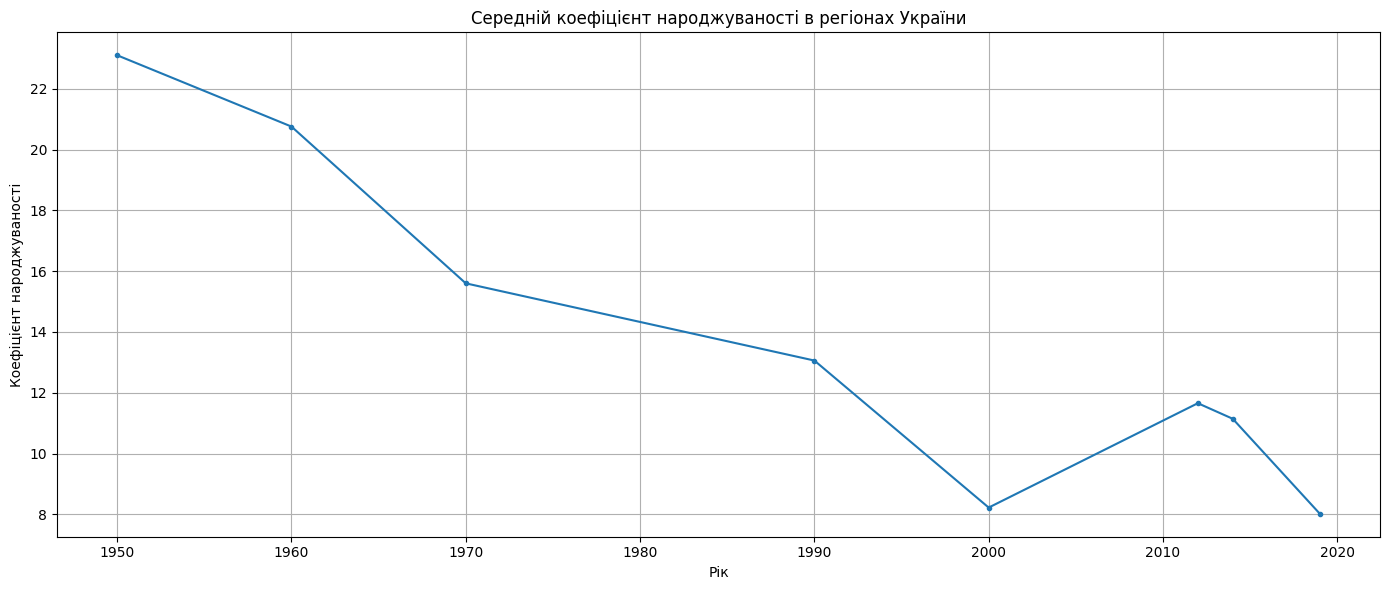

In [72]:
# Обчислення середнього значення за кожен рік
regional_df = df[
    ~df["Регіон"].astype(str).str.strip().str.lower().isin(
        ["україна", "всього", "разом"]
    )
]

mean_birth_rate = regional_df[year_cols].mean()

years = [int(col[:4]) if col[:4].isdigit()
         else int(next(y for y in range(1950, 2020) if str(y) in col))
         for col in year_cols]

plt.figure(figsize=(14, 6))
plt.plot(years, mean_birth_rate.values, marker="o", markersize=3)

plt.title("Середній коефіцієнт народжуваності в регіонах України")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності")
plt.grid(True)
plt.tight_layout()
plt.show()

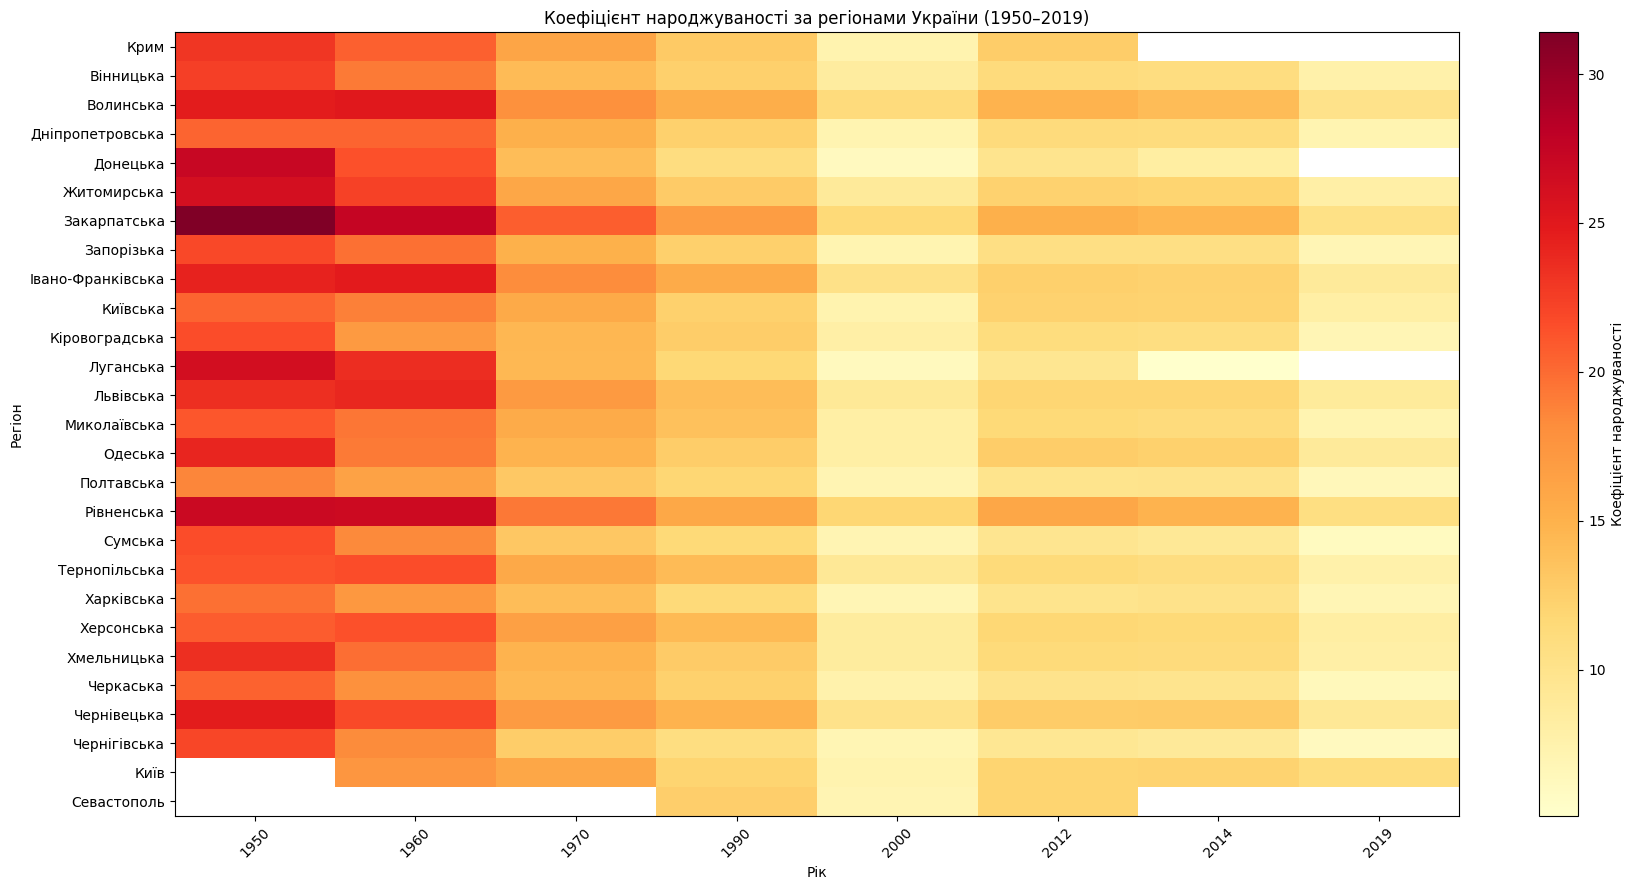

In [73]:
heatmap_data = regional_df.set_index("Регіон")[year_cols]

plt.figure(figsize=(18, 9))
plt.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest",
    cmap="YlOrRd"
)

plt.title("Коефіцієнт народжуваності за регіонами України (1950–2019)")
plt.xlabel("Рік")
plt.ylabel("Регіон")

step = max(1, len(year_cols) // 14)
positions = list(range(0, len(year_cols), step))

plt.xticks(
    positions,
    [years[i] for i in positions],
    rotation=45
)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)

plt.colorbar(label="Коефіцієнт народжуваності")
plt.tight_layout()
plt.show()

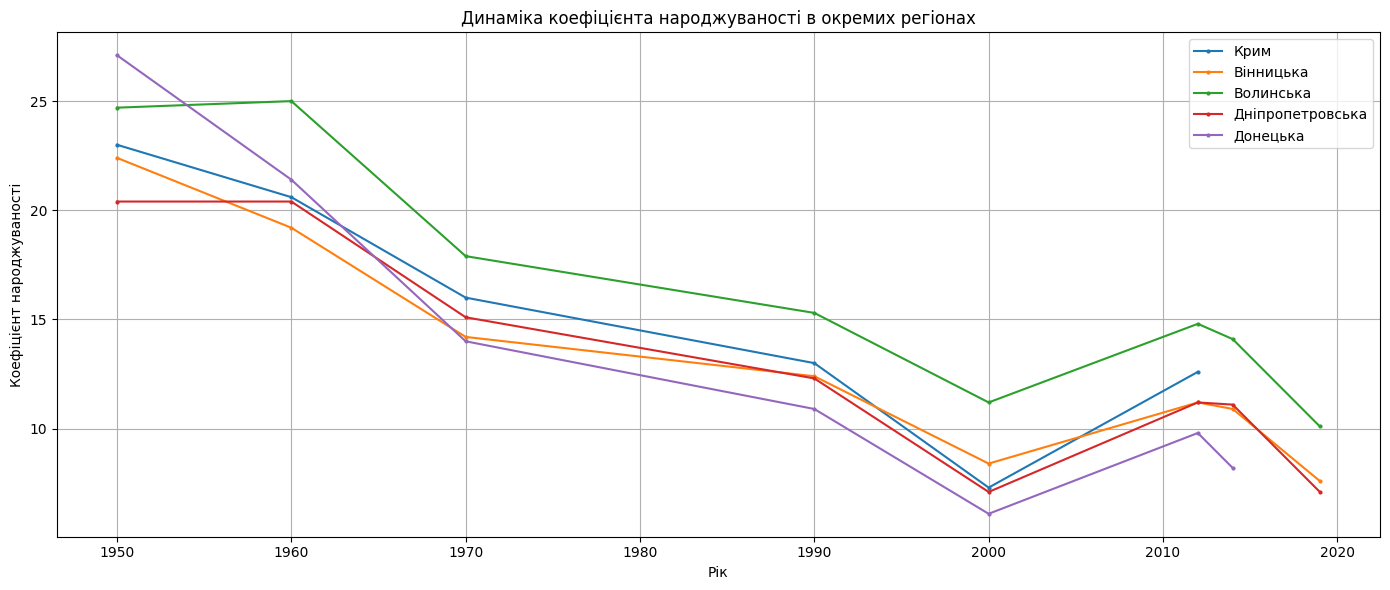

In [74]:
regions = regional_df["Регіон"].dropna().head(5).tolist()

plt.figure(figsize=(14, 6))

for region in regions:
    row = regional_df[regional_df["Регіон"] == region].iloc[0]
    plt.plot(
        years,
        row[year_cols].values,
        marker="o",
        markersize=2,
        label=region
    )

plt.title("Динаміка коефіцієнта народжуваності в окремих регіонах")
plt.xlabel("Рік")
plt.ylabel("Коефіцієнт народжуваності")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [75]:
# Рік із найвищим і найнижчим середнім значенням
print("Найвище середнє значення:",
      years[mean_birth_rate.values.argmax()],
      mean_birth_rate.max())

print("Найнижче середнє значення:",
      years[mean_birth_rate.values.argmin()],
      mean_birth_rate.min())

# Максимальний і мінімальний показники за останній рік
last_year = year_cols[-1]
last_data = regional_df[["Регіон", last_year]].dropna()

print("\nОстанній рік:", last_year)

print("Максимальний показник:")
print(last_data.loc[last_data[last_year].idxmax()])

print("\nМінімальний показник:")
print(last_data.loc[last_data[last_year].idxmin()])

Найвище середнє значення: 1950 23.103999999999996
Найнижче середнє значення: 2019 8.017391304347827

Останній рік: 2019
Максимальний показник:
Регіон    Київ
2019      11.0
Name: 25, dtype: object

Мінімальний показник:
Регіон    Сумська
2019          6.0
Name: 17, dtype: object
